# BirdCLEF 2026 — data preparation

Prepare manifests, fixed file-grouped folds and waveform datasets for a first baseline. This notebook uses the project package; the EDA notebook remains independent. No training, external downloads, automatic audio removal or unannotated negatives.

Select the repository `.venv` kernel after `uv sync --extra notebooks --extra deep-learning --extra audio`, as in the local starter. Run from the project root. Data and output paths come from the project config (`.env`): by default, `data/competition` and `outputs/data_prep`. Source audio is read in place.

In [1]:
import json
from hashlib import sha256

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import soundfile as sf
import torch
from IPython.display import display
from torch.utils.data import ConcatDataset, DataLoader
from tqdm.auto import tqdm

from birdclef.competition import class_columns
from birdclef.config import get_config
from birdclef.data import (
    FocalAudioDataset,
    SoundscapeDataset,
    SourceWeightedRandomSampler,
    filter_focal_duration,
    focal_manifest,
    group_folds,
    read_audio_window,
    soundscape_manifest,
)
from birdclef.processing import log_mel
from birdclef.runtime import apply_environment_defaults

apply_environment_defaults()
config = get_config()

ROOT = config.data.competition_dir
OUTPUT = config.data.output_dir / "data_prep"
N_FOLDS = 5
FOLD = 0
SEED = config.train.seed
MIN_FOCAL_SECONDS = 1.0
SOUNDSCAPE_PROBABILITY = config.loader.soundscape_probability

torch.manual_seed(SEED)


Detected environment: local
Loading default Config...


                                   Config                                    
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Setting                       ┃ Value                                     ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ app_name                      │ birdclef                                  │
│ logging.directory             │ C:\_GitHub\birdclef-2026\logs             │
│ logging.level                 │ INFO                                      │
│ logging.formatter             │ ColoredFormatter                          │
│ logging.date_format           │ %d-%m-%Y %H:%M:%S                         │
│ logging.full_color            │ True                                      │
│ logging.include_function      │ True                                      │
│ logging.success_level         │ 69                                        │
├───────────────────────────────┼───────────────────────────────────────────┤
│ data.competition_dir          │ C:\_GitHub\birdclef-2026\data\competition │
│ data.output_dir               │ C:\_GitHub\birdclef-2026\outputs          │
├───────────────────────────────┼───────────────────────────────────────────┤
│ split.validation_fraction     │ 0.2                                       │
│ split.seed                    │ 42                                        │
│ split.group_column            │ None                                      │
│ split.stratify                │ False                                     │
├───────────────────────────────┼───────────────────────────────────────────┤
│ tracking.project              │ birdclef-2026                             │
│ tracking.entity               │ None                                      │
│ tracking.offline              │ True                                      │
│ tracking.api_key              │ None                                      │
├───────────────────────────────┼───────────────────────────────────────────┤
│ loader.batch_size             │ 128                                       │
│ loader.val_batch_size         │ 32                                        │
│ loader.predict_batch_size     │ 32                                        │
│ loader.num_workers            │ 0                                         │
│ loader.pin_memory             │ False                                     │
│ loader.seed                   │ 0                                         │
│ loader.soundscape_probability │ 0.1                                       │
├───────────────────────────────┼───────────────────────────────────────────┤
│ lr_scheduler.name             │ none                                      │
│ lr_scheduler.t_max            │ 10                                        │
│ lr_scheduler.min_lr           │ 0.0                                       │
│ lr_scheduler.factor           │ 0.1                                       │
│ lr_scheduler.patience         │ 2                                         │
│ lr_scheduler.monitor          │ val/loss                                  │
│ lr_scheduler.mode             │ min                                       │
├───────────────────────────────┼───────────────────────────────────────────┤
│ train.max_epochs              │ 10                                        │
│ train.seed                    │ 42                                        │
│ train.checkpoint_metric       │ val/loss                                  │
│ train.checkpoint_mode         │ min                                       │
│ train.checkpoint_top_k        │ 1                                         │
│ train.early_stopping_patience │ 3                                         │
│ train.accumulate_grad_batches │ 1                                         │
│ train.gradient_clip_val       │ 1.0                                       │
│ train.log_every_n_steps       │ 10                                        │
├─────────────────────

## Labeled units and class order

Class order comes only from sample submission columns. Focal targets include primary and secondary labels and remain weak clip labels after cropping. Soundscape targets refer only to explicitly annotated five-second windows. Missing annotation rows never become negative examples. Identical annotation sets collapse; conflicting sets fail.

In [2]:
classes = class_columns(pd.read_csv(ROOT / "sample_submission.csv"))
focal, focal_targets = focal_manifest(
    pd.read_csv(ROOT / "train.csv", dtype={"primary_label": str}),
    ROOT / "train_audio",
    classes,
)
windows, window_targets = soundscape_manifest(
    pd.read_csv(ROOT / "train_soundscapes_labels.csv", dtype={"primary_label": str}),
    ROOT / "train_soundscapes",
    classes,
)
windows["fold"] = group_folds(windows, n_splits=N_FOLDS)
display(
    pd.Series(
        {
            "classes": len(classes),
            "focal_clips": len(focal),
            "annotated_windows": len(windows),
            "annotated_files": windows.filename.nunique(),
        }
    )
)
display(windows.head())


classes                234
focal_clips          35549
annotated_windows      739
annotated_files         66
dtype: int64

,filename,start,end,path,row_id,fold
0,BC2026_Train_0001_S08_20250606_030007.ogg,0.0,5.0,C:\_GitHub\birdclef-2026\data\competition\trai...,BC2026_Train_0001_S08_20250606_030007_5,3
1,BC2026_Train_0001_S08_20250606_030007.ogg,5.0,10.0,C:\_GitHub\birdclef-2026\data\competition\trai...,BC2026_Train_0001_S08_20250606_030007_10,3
2,BC2026_Train_0001_S08_20250606_030007.ogg,10.0,15.0,C:\_GitHub\birdclef-2026\data\competition\trai...,BC2026_Train_0001_S08_20250606_030007_15,3
3,BC2026_Train_0001_S08_20250606_030007.ogg,15.0,20.0,C:\_GitHub\birdclef-2026\data\competition\trai...,BC2026_Train_0001_S08_20250606_030007_20,3
4,BC2026_Train_0001_S08_20250606_030007.ogg,20.0,25.0,C:\_GitHub\birdclef-2026\data\competition\trai...,BC2026_Train_0001_S08_20250606_030007_25,3


## Freeze folds and inspect AUC eligibility

Zero-based GroupKFold assignments keep all windows of a recording together. This is unstratified file CV, not a site independence guarantee. All focal recordings are available for training; no acoustic duplicate or geographic leakage audit is implied.

Save assignments before filtering or sampling. Do not average fold macro AUC scores without reporting their different evaluated class sets. Pooled OOF also compares scores from different models. Classes without negatives still block the competition metric; this table diagnoses them and does not silently change the metric.

In [3]:
support_rows = []
for fold in range(N_FOLDS):
    valid = windows.fold.eq(fold)
    assert not set(windows.loc[valid, "filename"]) & set(windows.loc[~valid, "filename"])
    positive = window_targets.loc[windows.loc[valid, "row_id"]].sum()
    negative = int(valid.sum()) - positive
    training_positive = window_targets.loc[windows.loc[~valid, "row_id"]].sum()
    for label in classes:
        support_rows.append(
            {
                "fold": fold,
                "species": label,
                "train_positive_windows": int(training_positive[label]),
                "valid_positive_windows": int(positive[label]),
                "valid_negative_windows": int(negative[label]),
                "auc_defined": bool(positive[label] > 0 and negative[label] > 0),
            }
        )
support = pd.DataFrame(support_rows)
display(
    support.groupby("fold").agg(
        auc_defined_classes=("auc_defined", "sum"),
        classes_without_positives=("valid_positive_windows", lambda x: x.eq(0).sum()),
        classes_without_negatives=("valid_negative_windows", lambda x: x.eq(0).sum()),
    )
)


,auc_defined_classes,classes_without_positives,classes_without_negatives
fold,,,
0,28,206,0
1,34,200,0
2,36,198,0
3,46,188,0
4,39,195,0


## Header audit and duration policy

Read headers, not entire recordings. Focal recordings shorter than one second are excluded from the prepared training manifest and listed in `short_recordings_review.csv`; source files are untouched. A recording exactly one second long is retained. Header failures block preparation. This is not a complete decode or acoustic-duplicate audit.

Compare class support before and after filtering, including weak secondary labels. Report classes losing every focal example; do not silently restore excluded clips.

In [4]:
header_rows = []
sources = pd.concat(
    [
        focal[["filename", "path"]].assign(source="focal"),
        windows[["filename", "path"]].drop_duplicates().assign(source="soundscape"),
    ],
    ignore_index=True,
)
for row in tqdm(sources.itertuples(index=False), total=len(sources)):
    result: dict[str, object] = {"source": row.source, "filename": row.filename}
    try:
        info = sf.info(str(row.path))
        result.update(
            duration=info.duration,
            sample_rate=info.samplerate,
            channels=info.channels,
            frames=info.frames,
            error=None,
        )
    except (OSError, RuntimeError) as error:
        result["error"] = f"{type(error).__name__}: {error}"
    header_rows.append(result)
headers = pd.DataFrame(
    header_rows,
    columns=[
        "source",
        "filename",
        "duration",
        "sample_rate",
        "channels",
        "frames",
        "error",
    ],
)
if headers.error.notna().any() or headers.frames.eq(0).any():
    display(headers.loc[headers.error.notna() | headers.frames.eq(0)])
    raise ValueError("Repair failed or empty audio files before preparing training data.")
focal_before_filter = len(focal)
focal_class_counts_before = focal_targets.sum()
focal, focal_targets, short_recordings = filter_focal_duration(
    focal,
    focal_targets,
    headers.loc[headers.source.eq("focal")],
    min_duration=MIN_FOCAL_SECONDS,
)
display(
    pd.Series(
        {
            "focal_before": focal_before_filter,
            "focal_retained": len(focal),
            "focal_excluded": len(short_recordings),
        }
    )
)
display(short_recordings[["filename", "duration"]])

focal_coverage = pd.DataFrame(
    {
        "before_filter": focal_class_counts_before,
        "after_filter": focal_targets.sum(),
    }
)
lost_focal_classes = focal_coverage.index[
    focal_coverage.before_filter.gt(0) & focal_coverage.after_filter.eq(0)
].tolist()
display(focal_coverage)
print("Classes losing all focal supervision:", lost_focal_classes)


  0%|          | 0/35615 [00:00<?, ?it/s]

focal_before      35549
focal_retained    35179
focal_excluded      370
dtype: int64

,filename,duration
8,1161364/iNat1264238.ogg,0.288000
29,209233/iNat1545859.ogg,0.144000
39,22956/iNat1693371.ogg,0.576000
127,22973/iNat781822.ogg,0.048000
128,22973/iNat1353836.ogg,0.096000
...,...,...
34794,yecpar/iNat1360878.ogg,0.208969
34868,yecpar/iNat1347445.ogg,0.156750
35006,yehcar1/iNat1268927.ogg,0.017406
35026,yehcar1/iNat585409.ogg,0.072000


,before_filter,after_filter
1161364,11.0,10.0
116570,1.0,1.0
1176823,12.0,12.0
1491113,0.0,0.0
1595929,5.0,5.0
...,...,...
yebela1,384.0,381.0
yecmac,50.0,50.0
yecpar,469.0,467.0
yehcar1,82.0,79.0


Classes losing all focal supervision: []


## Save portable manifests and provenance

Saved CSVs use filenames rather than machine-specific absolute paths. Rebuild paths against `ROOT` after loading. Target columns follow `classes.json` exactly. SHA-256 hashes bind metadata, targets and fold assignments; the original CSV hashes record provenance. Audio content is not hashed. No source recordings are copied.

Targets carry their own identity: `filename` for focal clips, `row_id` for windows. Load them with `index_col` and let datasets align by key, rather than trusting CSV row order. This replaces older target CSVs without keys.

In [5]:
OUTPUT.mkdir(parents=True, exist_ok=True)
focal.drop(columns="path").to_csv(OUTPUT / "focal.csv", index=False)
focal_targets.to_csv(OUTPUT / "focal_targets.csv", index=True)
windows.drop(columns="path").to_csv(OUTPUT / "soundscapes.csv", index=False)
window_targets.to_csv(OUTPUT / "soundscape_targets.csv", index=True)
support.to_csv(OUTPUT / "fold_class_support.csv", index=False)
headers.to_csv(OUTPUT / "audio_headers.csv", index=False)
short_recordings.drop(columns="path").to_csv(OUTPUT / "short_recordings_review.csv", index=False)
(OUTPUT / "classes.json").write_text(json.dumps(classes, indent=2), encoding="utf-8")
artifact_names = [
    "focal.csv",
    "focal_targets.csv",
    "soundscapes.csv",
    "soundscape_targets.csv",
    "fold_class_support.csv",
    "classes.json",
    "audio_headers.csv",
    "short_recordings_review.csv",
]
provenance = {
    "version": 2,
    "protocol": "GroupKFold",
    "group_column": "filename",
    "n_folds": N_FOLDS,
    "fold_numbering": "zero-based",
    "include_secondary": True,
    "min_focal_seconds": MIN_FOCAL_SECONDS,
    "target_keys": {"focal": "filename", "soundscape": "row_id"},
    "artifacts_sha256": {
        name: sha256((OUTPUT / name).read_bytes()).hexdigest() for name in artifact_names
    },
    "source_csv_sha256": {
        name: sha256((ROOT / name).read_bytes()).hexdigest()
        for name in [
            "train.csv",
            "train_soundscapes_labels.csv",
            "sample_submission.csv",
        ]
    },
}
(OUTPUT / "manifest.json").write_text(json.dumps(provenance, indent=2), encoding="utf-8")
print(f"Prepared artifacts: {OUTPUT}")


Prepared artifacts: C:\_GitHub\birdclef-2026\outputs\data_prep


## Dataset and inference smoke checks

The dataset owns decoding, resampling, crops and targets. `log_mel` is an optional CPU frontend: mono 32 kHz, FFT 1024, hop 320, 128 Mel bands, 50–14,000 Hz, no centering, power dB re 1 with 80 dB range. Five seconds produce `(1, 128, 497)`. No peak normalization or training is performed.

Focal training crops are random; evaluation crops are centered; retained clips shorter than five seconds are right-padded. Soundscape windows are exact and truncated windows fail. Keep loader RNG seeds fixed for reproducibility. The current numeric MLP is not an audio model and should not receive spectrograms directly.

In [6]:
assert focal_targets.columns.tolist() == classes, "Focal target class order mismatch."
assert window_targets.columns.tolist() == classes, "Soundscape target class order mismatch."

train_mask = windows.fold.ne(FOLD)
valid_mask = ~train_mask
focal_dataset = FocalAudioDataset(focal, focal_targets, training=True, transform=log_mel)
sc_train = SoundscapeDataset(
    windows.loc[train_mask],
    window_targets.loc[windows.loc[train_mask, "row_id"]],
    transform=log_mel,
)
sc_valid = SoundscapeDataset(
    windows.loc[valid_mask],
    window_targets.loc[windows.loc[valid_mask, "row_id"]],
    transform=log_mel,
)
training = ConcatDataset([focal_dataset, sc_train])
sampler = SourceWeightedRandomSampler(
    len(focal_dataset),
    len(sc_train),
    soundscape_probability=SOUNDSCAPE_PROBABILITY,
    generator=torch.Generator().manual_seed(SEED),
)
loader = DataLoader(
    training,
    batch_size=2,
    sampler=sampler,
    num_workers=0,
    generator=torch.Generator().manual_seed(SEED),
)
inputs, targets = next(iter(loader))
assert inputs.shape == (2, 1, 128, 497)
assert targets.shape == (2, len(classes))
assert torch.isfinite(inputs).all()
valid_input, valid_target = sc_valid[0]
assert valid_input.shape == (1, 128, 497)
assert valid_target.shape == (len(classes),)

path = windows.path.iloc[0]
features = torch.stack([log_mel(read_audio_window(path, start=start)) for start in range(0, 60, 5)])
assert features.shape == (12, 1, 128, 497)
print(
    {
        "train_examples": len(training),
        "valid_windows": len(sc_valid),
        "batch_shape": tuple(inputs.shape),
        "one_soundscape_shape": tuple(features.shape),
    }
)


{'train_examples': 35769, 'valid_windows': 149, 'batch_shape': (2, 1, 128, 497), 'one_soundscape_shape': (12, 1, 128, 497)}


## Source sampling as a training hyperparameter

`config.loader.soundscape_probability` is the initial expected soundscape fraction (default 0.1). Every sample within a source has equal weight: `(1-p)/N_focal` and `p/N_soundscape`. Sampling uses replacement; this controls source frequency, not class balancing or an exact per-batch quota. `num_samples` controls epoch length independently.

Call `sampler.set_soundscape_probability(0.3)` **between epochs**, or in a training callback before a new iterator is created. The same loader can be reused; model weights and prepared artifacts need no changes. An active iterator already drew all its indices, and prefetched batches do not change. With Lightning, pass `sampler=sampler` to `TrainingDataModule`. Validation stays sequential and unweighted. Multi-device distributed sampling needs its own design before using this sampler.

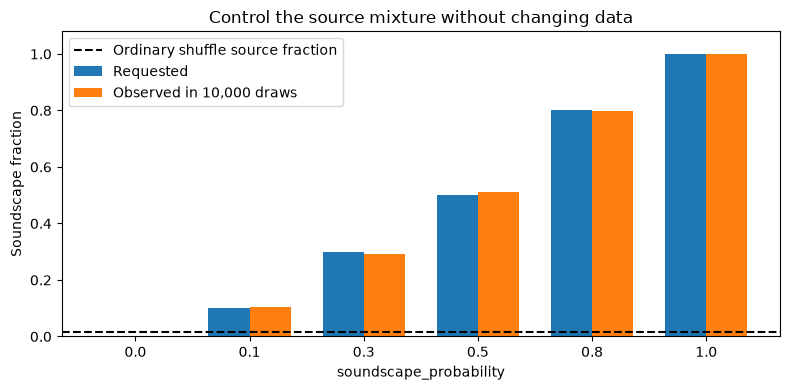

In [7]:
probabilities = [0.0, 0.1, 0.3, 0.5, 0.8, 1.0]
observed = []
preview_sampler = SourceWeightedRandomSampler(
    len(focal_dataset),
    len(sc_train),
    soundscape_probability=0.5,
    num_samples=10000,
    generator=torch.Generator().manual_seed(SEED),
)
for probability in probabilities:
    preview_sampler.set_soundscape_probability(probability)
    draws = np.array(list(preview_sampler))  # indices only; no audio decoding
    observed.append((draws >= len(focal_dataset)).mean())
fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(len(probabilities))
ax.bar(x - 0.18, probabilities, width=0.36, label="Requested")
ax.bar(x + 0.18, observed, width=0.36, label="Observed in 10,000 draws")
ax.axhline(
    len(sc_train) / len(training),
    color="black",
    linestyle="--",
    label="Ordinary shuffle source fraction",
)
ax.set(
    xticks=x,
    xticklabels=probabilities,
    xlabel="soundscape_probability",
    ylabel="Soundscape fraction",
    ylim=(0, 1.08),
    title="Control the source mixture without changing data",
)
ax.legend()
fig.tight_layout()
plt.show()


## Follow one recording through preprocessing

The same example passes through native decoding, mono downmix, centered crop, resampling/right padding, and Log-Mel. The shaded region is the selected crop; axes keep explicit units. The target strip shows weak **clip** labels, not proof of vocalization within this crop. No amplitude normalization is applied.

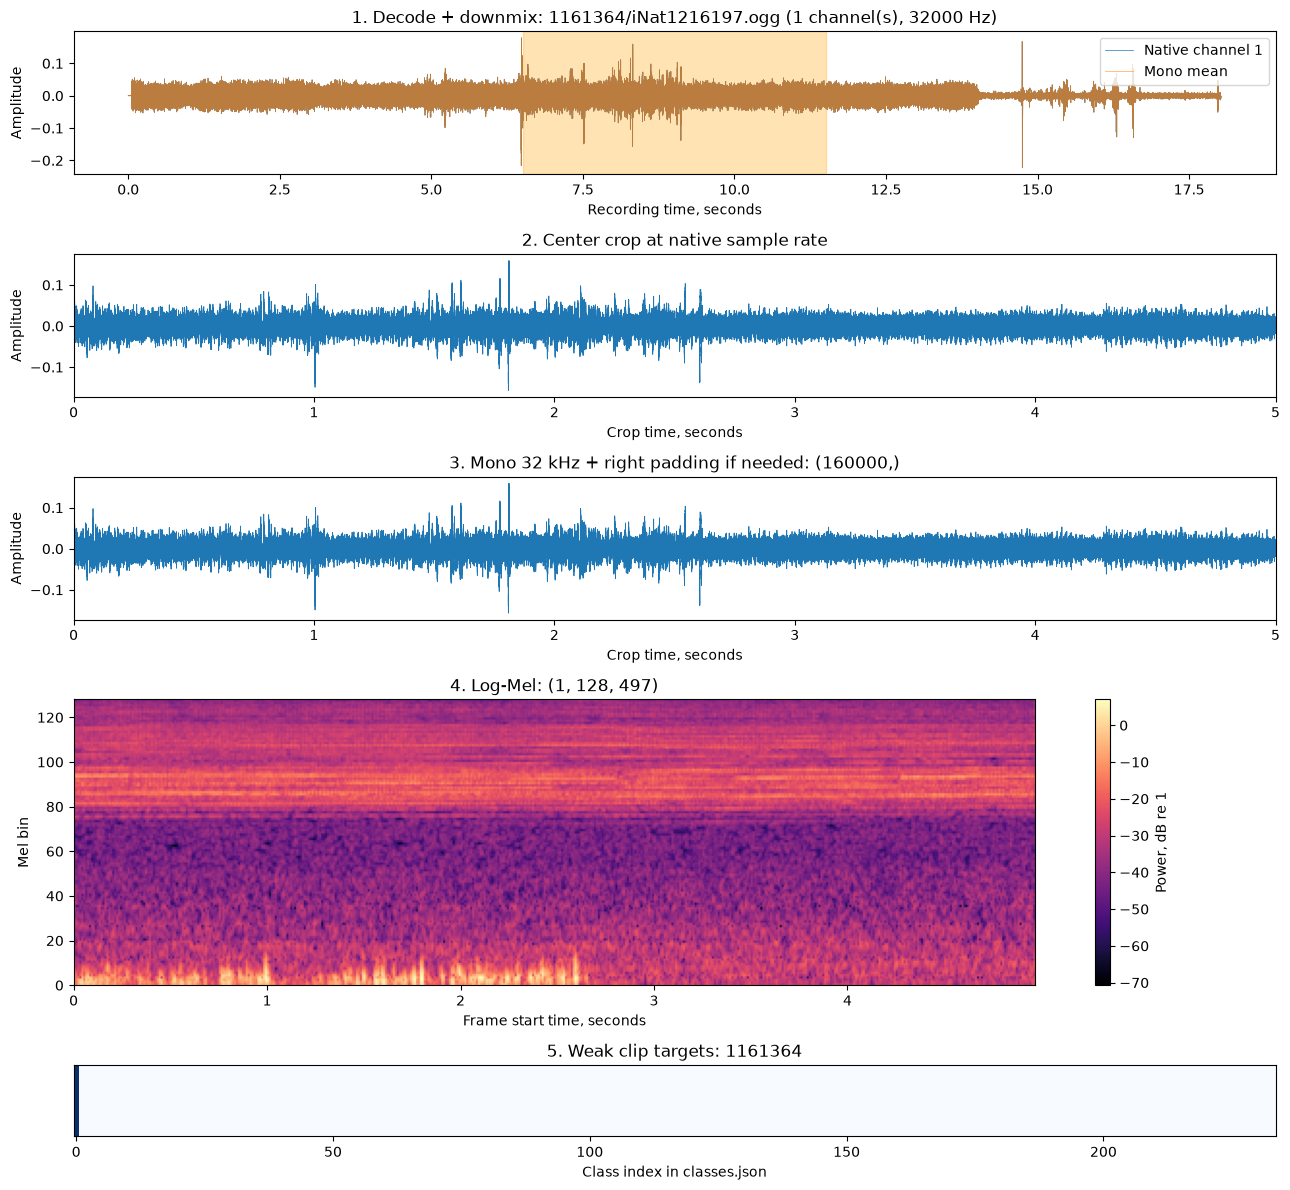

,stage,shape,meaning
0,Decoded,"(576768, 1)",32000 Hz
1,Mono,"(576768,)",32000 Hz
2,Crop,"(160000,)",32000 Hz
3,Resample / pad,"(160000,)",32000 Hz
4,Log-Mel,"(1, 128, 497)",128 Mel bins
5,Targets,"(234,)",weak clip labels


In [8]:
duration_by_name = headers.loc[headers.source.eq("focal")].set_index("filename").duration
candidates = focal.loc[focal.filename.map(duration_by_name).between(6, 30)]
example = candidates.iloc[0] if len(candidates) else focal.iloc[0]
native, native_rate = sf.read(example.path, dtype="float32", always_2d=True)
mono = native.mean(axis=1)
start_frame = max(0, (len(mono) - 5 * native_rate) // 2)
start_seconds = start_frame / native_rate
crop = mono[start_frame : start_frame + 5 * native_rate]
prepared = read_audio_window(example.path, start=start_seconds, pad=True)
mel = log_mel(prepared)[0].numpy()
example_targets = focal_targets.loc[example.filename]
active_labels = example_targets.index[example_targets.eq(1)].tolist()

fig, axes = plt.subplots(5, 1, figsize=(13, 12), gridspec_kw={"height_ratios": [1, 1, 1, 2, 0.5]})
t = np.arange(len(mono)) / native_rate
axes[0].plot(t, native[:, 0], lw=0.5, label="Native channel 1")
axes[0].plot(t, mono, lw=0.5, alpha=0.7, label="Mono mean")
axes[0].axvspan(
    start_seconds, min(start_seconds + 5, len(mono) / native_rate), color="orange", alpha=0.3
)
axes[0].set(
    title=f"1. Decode + downmix: {example.filename} ({native.shape[1]} channel(s), {native_rate} Hz)",
    xlabel="Recording time, seconds",
    ylabel="Amplitude",
)
axes[0].legend(loc="upper right")
axes[1].plot(np.arange(len(crop)) / native_rate, crop, lw=0.6)
axes[1].set(
    title="2. Center crop at native sample rate",
    xlabel="Crop time, seconds",
    ylabel="Amplitude",
    xlim=(0, 5),
)
axes[2].plot(np.arange(len(prepared)) / 32000, prepared.numpy(), lw=0.6)
axes[2].set(
    title=f"3. Mono 32 kHz + right padding if needed: {tuple(prepared.shape)}",
    xlabel="Crop time, seconds",
    ylabel="Amplitude",
    xlim=(0, 5),
)
image = axes[3].imshow(
    mel, origin="lower", aspect="auto", extent=[0, mel.shape[1] * 0.01, 0, 128], cmap="magma"
)
axes[3].set(
    title=f"4. Log-Mel: (1, {mel.shape[0]}, {mel.shape[1]})",
    xlabel="Frame start time, seconds",
    ylabel="Mel bin",
)
fig.colorbar(image, ax=axes[3], label="Power, dB re 1")
axes[4].imshow(example_targets.to_numpy()[None, :], aspect="auto", vmin=0, vmax=1, cmap="Blues")
axes[4].set(
    title=f"5. Weak clip targets: {', '.join(active_labels)}",
    xlabel="Class index in classes.json",
    yticks=[],
)
fig.tight_layout()
plt.show()

display(
    pd.DataFrame(
        [
            ("Decoded", str(native.shape), f"{native_rate} Hz"),
            ("Mono", str(mono.shape), f"{native_rate} Hz"),
            ("Crop", str(crop.shape), f"{native_rate} Hz"),
            ("Resample / pad", str(tuple(prepared.shape)), "32000 Hz"),
            ("Log-Mel", str((1, *mel.shape)), "128 Mel bins"),
            ("Targets", str(example_targets.shape), "weak clip labels"),
        ],
        columns=["stage", "shape", "meaning"],
    )
)


## CSV identity round trip

Targets remain attached to their identifiers even when metadata and target rows are independently reordered. Datasets validate complete key coverage before constructing samples.

In [9]:
reloaded_focal = pd.read_csv(OUTPUT / "focal.csv")
reloaded_targets = pd.read_csv(OUTPUT / "focal_targets.csv", index_col="filename")
reloaded_focal["path"] = [
    str(ROOT / "train_audio" / name) for name in reloaded_focal.filename.tolist()
]
round_trip = FocalAudioDataset(
    reloaded_focal.iloc[::-1].reset_index(drop=True),
    reloaded_targets.sample(frac=1, random_state=SEED),
    training=False,
)
np.testing.assert_array_equal(
    round_trip.targets[0].numpy(), reloaded_targets.loc[reloaded_focal.filename.iloc[-1]].to_numpy()
)
print("CSV targets align by filename after independent row reordering.")


CSV targets align by filename after independent row reordering.
